In [2]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parent   # le notebook est dans notebooks/
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import wfdb
from scipy import signal as sps
from scipy import stats

from src.data.constants import (ALL_RECORDS, PACED_RECORDS, DS1, DS2, AAMI_MAP,
                                CLASS_ORDER, SYMBOL_DESCRIPTIONS, FS)
from src.data.loader import load_record, build_beat_table

DATA_DIR = PROJECT_ROOT / "data" / "raw" / "mitdb"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42
sns.set_theme(style="whitegrid")
COLORS = {"N": "tab:green", "S": "tab:orange", "V": "tab:red",
          "F": "tab:purple", "Q": "tab:gray"}
print("Dossier de données :", DATA_DIR, "| existe :", DATA_DIR.exists())

Dossier de données : C:\Users\HUAWEI\heartbeat-classifier\data\raw\mitdb | existe : True


In [3]:
for ext in ("dat", "hea", "atr"):
    print(ext, "->", len(list(DATA_DIR.glob(f"*.{ext}"))), "fichiers")

print("\nFichiers du record 100 :", [p.name for p in sorted(DATA_DIR.glob("100.*"))])
print("\n--- Contenu du .hea (texte lisible) ---")
print((DATA_DIR / "100.hea").read_text())

dat -> 48 fichiers
hea -> 48 fichiers
atr -> 48 fichiers

Fichiers du record 100 : ['100.atr', '100.dat', '100.hea']

--- Contenu du .hea (texte lisible) ---
100 2 360 650000
100.dat 212 200 11 1024 995 -22131 0 MLII
100.dat 212 200 11 1024 1011 20052 0 V5
# 69 M 1085 1629 x1
# Aldomet, Inderal



In [4]:
path100 = str(DATA_DIR / "100")
rec_phys = wfdb.rdrecord(path100)                    # mV
rec_dig = wfdb.rdrecord(path100, physical=False)     # entiers bruts

print("Noms des canaux :", rec_phys.sig_name)
print("Unités :", rec_phys.units, "| fs :", rec_phys.fs, "| longueur :", rec_phys.sig_len)
print("Gain :", rec_dig.adc_gain, "| baseline :", rec_dig.baseline)
print("Entiers bruts (5 premiers, canal 0) :", rec_dig.d_signal[:5, 0])
print("mV (5 premiers, canal 0)            :", rec_phys.p_signal[:5, 0].round(3))

# Vérification de la formule : physique = (digital - baseline) / gain
recomputed = (rec_dig.d_signal - np.array(rec_dig.baseline)) / np.array(rec_dig.adc_gain)
print("Formule vérifiée :", np.allclose(recomputed, rec_phys.p_signal, atol=1e-6))

Noms des canaux : ['MLII', 'V5']
Unités : ['mV', 'mV'] | fs : 360 | longueur : 650000
Gain : [200.0, 200.0] | baseline : [1024, 1024]
Entiers bruts (5 premiers, canal 0) : [995 995 995 995 995]
mV (5 premiers, canal 0)            : [-0.145 -0.145 -0.145 -0.145 -0.145]
Formule vérifiée : True


In [5]:
signals = {}
for rid in ALL_RECORDS:
    signals[rid] = load_record(rid, DATA_DIR).signal   # MLII par son nom

all_ann, beats = build_beat_table(ALL_RECORDS, DATA_DIR)
print("Annotations totales :", len(all_ann), "| battements annotés :", len(beats))
print(beats.head())

[WARN] record 102 : MLII absente ['V5', 'V2'], utilisation de V5
[WARN] record 104 : MLII absente ['V5', 'V2'], utilisation de V5
Annotations totales : 112647 | battements annotés : 109494
  record_id  sample symbol aami
0       100      77      N    N
1       100     370      N    N
2       100     662      N    N
3       100     946      N    N
4       100    1231      N    N


In [6]:
a100 = all_ann[all_ann.record_id == "100"]
print(a100.head(10))
print("\nSymboles du record 100 :\n", a100.symbol.value_counts())

# Annotations de type "rythme" : le texte associé est dans aux_note
ann100 = wfdb.rdann(path100, "atr")
print("\naux_note non vides :", [x for x in ann100.aux_note if x][:5])

  record_id  sample symbol
0       100      18      +
1       100      77      N
2       100     370      N
3       100     662      N
4       100     946      N
5       100    1231      N
6       100    1515      N
7       100    1809      N
8       100    2044      A
9       100    2402      N

Symboles du record 100 :
 symbol
N    2239
A      33
+       1
V       1
Name: count, dtype: int64

aux_note non vides : ['(N\x00']


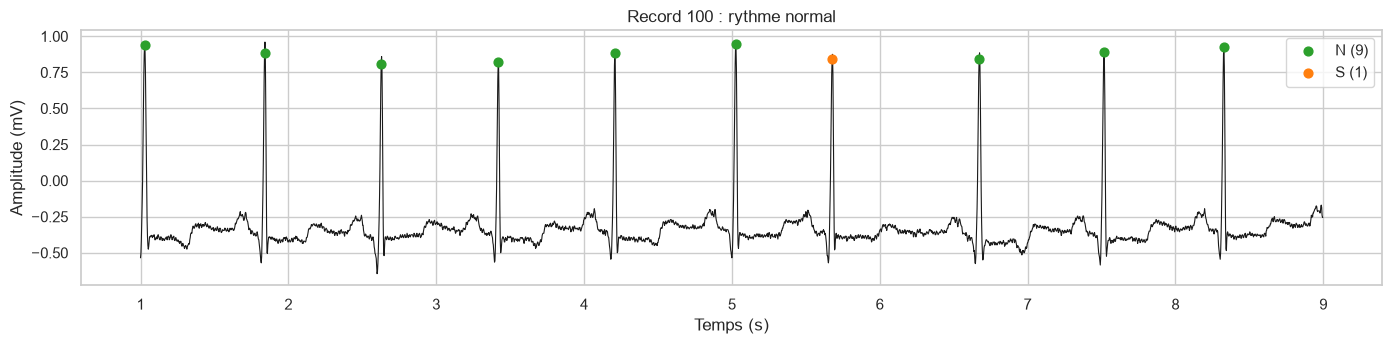

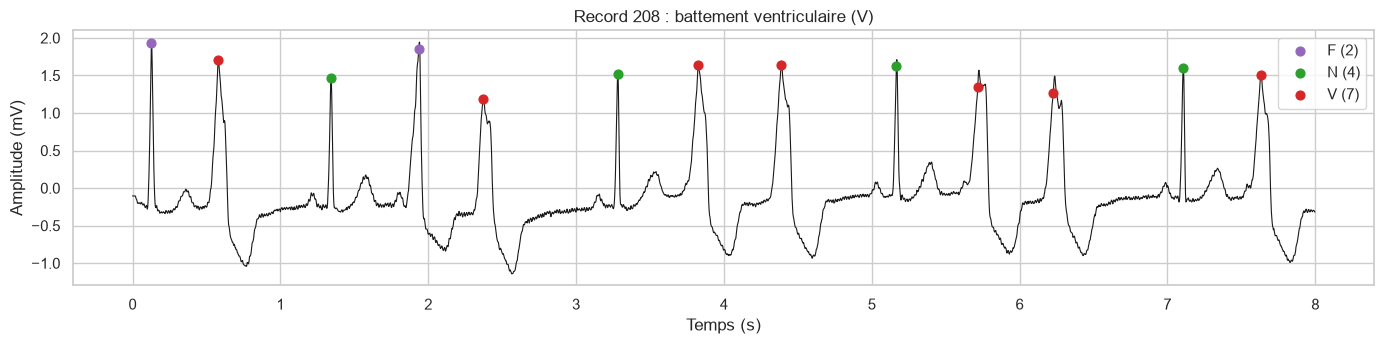

In [7]:
def plot_segment(record_id, center_sample, dur_s=8, title=""):
    x = signals[record_id]
    i0 = max(0, int(center_sample - dur_s / 2 * FS))
    i1 = min(len(x), i0 + int(dur_s * FS))
    t = np.arange(i0, i1) / FS
    fig, ax = plt.subplots(figsize=(14, 3.6))
    ax.plot(t, x[i0:i1], lw=0.8, color="k")
    b = beats[(beats.record_id == record_id) & (beats["sample"] >= i0) & (beats["sample"] < i1)]
    for cls, g in b.groupby("aami"):
        ax.scatter(g["sample"] / FS, x[g["sample"].values], s=40, c=COLORS[cls],
                   label=f"{cls} ({len(g)})", zorder=3)
    ax.set(xlabel="Temps (s)", ylabel="Amplitude (mV)", title=title or f"Record {record_id}")
    ax.legend(loc="upper right")
    plt.tight_layout()
    return fig

# 1) Un segment du record 100 (surtout normal)
fig = plot_segment("100", center_sample=5 * FS, title="Record 100 : rythme normal")
fig.savefig(FIG_DIR / "segment_record100.png", dpi=150)

# 2) Un segment autour d'un battement V, dans le record qui en contient le plus
rid_v = beats[beats.aami == "V"].record_id.value_counts().index[0]
first_v = int(beats[(beats.record_id == rid_v) & (beats.aami == "V")]["sample"].iloc[0])
fig = plot_segment(rid_v, first_v, title=f"Record {rid_v} : battement ventriculaire (V)")
fig.savefig(FIG_DIR / "segment_with_V.png", dpi=150)

Décalage annotation -> extremum (échantillons), statistiques :
count    2272.00
mean        0.54
std         0.55
min        -1.00
25%         0.00
50%         1.00
75%         1.00
max         3.00
dtype: float64


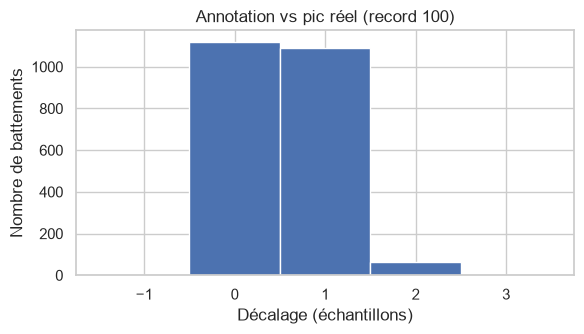

In [8]:
x = signals["100"]
b100 = beats[beats.record_id == "100"]["sample"].values
HALF = int(0.05 * FS)  # fenêtre de ±50 ms

offsets = []
for s in b100:
    if s - HALF < 0 or s + HALF >= len(x):
        continue
    w = x[s - HALF: s + HALF + 1]
    offsets.append(int(np.argmax(np.abs(w - np.median(w)))) - HALF)
offsets = np.array(offsets)

print("Décalage annotation -> extremum (échantillons), statistiques :")
print(pd.Series(offsets).describe().round(2))
plt.figure(figsize=(6, 3.5))
plt.hist(offsets, bins=np.arange(offsets.min() - 0.5, offsets.max() + 1.5, 1))
plt.xlabel("Décalage (échantillons)"); plt.ylabel("Nombre de battements")
plt.title("Annotation vs pic réel (record 100)"); plt.tight_layout()

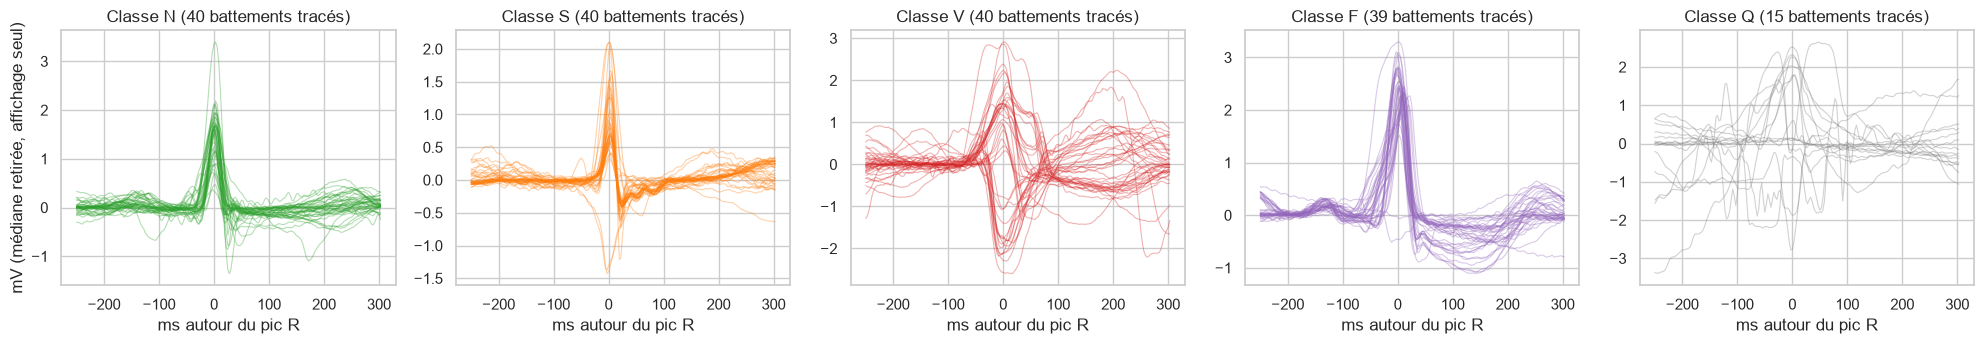

In [9]:
PRE, POST = 90, 110   # valeurs PROVISOIRES, justifiées en Phase 3
t_ms = np.arange(-PRE, POST) / FS * 1000
usable = beats[~beats.record_id.isin(PACED_RECORDS)]

fig, axes = plt.subplots(1, 5, figsize=(20, 3.6))
for ax, cls in zip(axes, CLASS_ORDER):
    sub = usable[usable.aami == cls]
    if sub.empty:
        ax.set_title(f"{cls} : aucun battement"); continue
    pick = sub.sample(n=min(40, len(sub)), random_state=SEED)
    n_plot = 0
    for _, row in pick.iterrows():
        s, sig = int(row["sample"]), signals[row["record_id"]]
        if s - PRE < 0 or s + POST > len(sig):
            continue
        seg = sig[s - PRE: s + POST]
        ax.plot(t_ms, seg - np.median(seg), alpha=0.35, lw=0.8, color=COLORS[cls])
        n_plot += 1
    ax.set(title=f"Classe {cls} ({n_plot} battements tracés)", xlabel="ms autour du pic R")
axes[0].set_ylabel("mV (médiane retirée, affichage seul)")
plt.tight_layout()
fig.savefig(FIG_DIR / "beats_per_class.png", dpi=150)

In [10]:
rows = []
for rid in ALL_RECORDS:
    h = wfdb.rdheader(str(DATA_DIR / rid))
    rows.append({"record_id": rid, "fs": h.fs, "sig_len": h.sig_len,
                 "duree_min": round(h.sig_len / h.fs / 60, 2),
                 "leads": tuple(h.sig_name), "MLII_present": "MLII" in h.sig_name})
meta = pd.DataFrame(rows)
print("Valeurs de fs :", meta.fs.unique())
print("Durée min/max (min) :", meta.duree_min.min(), meta.duree_min.max())
print("Records sans MLII :", meta[~meta.MLII_present].record_id.tolist())
print(meta.leads.value_counts())
print(f"Fréquence de Nyquist = fs/2 = {FS/2} Hz")

Valeurs de fs : [360]
Durée min/max (min) : 30.09 30.09
Records sans MLII : ['102', '104']
leads
(MLII, V1)    40
(MLII, V5)     2
(V5, V2)       2
(MLII, V2)     2
(V5, MLII)     1
(MLII, V4)     1
Name: count, dtype: int64
Fréquence de Nyquist = fs/2 = 180.0 Hz


In [11]:
q = []
for rid in ALL_RECORDS:
    x = signals[rid]
    s = beats[beats.record_id == rid]["sample"].values
    q.append({
        "record_id": rid,
        "n_nan": int(np.isnan(x).sum()),
        "n_inf": int(np.isinf(x).sum()),
        "part_plate_%": round(100 * float((np.diff(x) == 0).mean()), 2),
        "annot_hors_signal": int(((s < 0) | (s >= len(x))).sum()),
        "annot_triees": bool(np.all(np.diff(s) >= 0)),
    })
qual = pd.DataFrame(q)
print("Total NaN :", qual.n_nan.sum(), "| Total inf :", qual.n_inf.sum())
print("Annotations hors signal :", qual.annot_hors_signal.sum())
print("Annotations toutes triées :", qual.annot_triees.all())
print(qual.sort_values("part_plate_%", ascending=False).head(5))

Total NaN : 0 | Total inf : 0
Annotations hors signal : 0
Annotations toutes triées : True
   record_id  n_nan  n_inf  part_plate_%  annot_hors_signal  annot_triees
27       205      0      0         19.39                  0          True
19       121      0      0         17.71                  0          True
24       201      0      0         17.71                  0          True
14       115      0      0         17.49                  0          True
22       124      0      0         16.72                  0          True


         mean     std     min     max      p1     p99    skew  kurtosis
count  48.000  48.000  48.000  48.000  48.000  48.000  48.000    48.000
mean   -0.334   0.368  -2.635   2.469  -1.142   1.127   1.752    10.090
std     0.272   0.145   0.911   0.831   0.532   0.538   1.262     5.690
min    -0.936   0.165  -5.120   0.710  -2.525  -0.165  -0.929     0.799
25%    -0.494   0.266  -3.145   2.027  -1.479   0.775   0.875     5.760
50%    -0.200   0.342  -2.705   2.500  -1.050   1.198   1.848     9.174
75%    -0.161   0.436  -2.032   2.929  -0.724   1.505   2.746    13.350
max     0.069   0.858  -1.120   5.115  -0.465   2.275   4.426    25.413


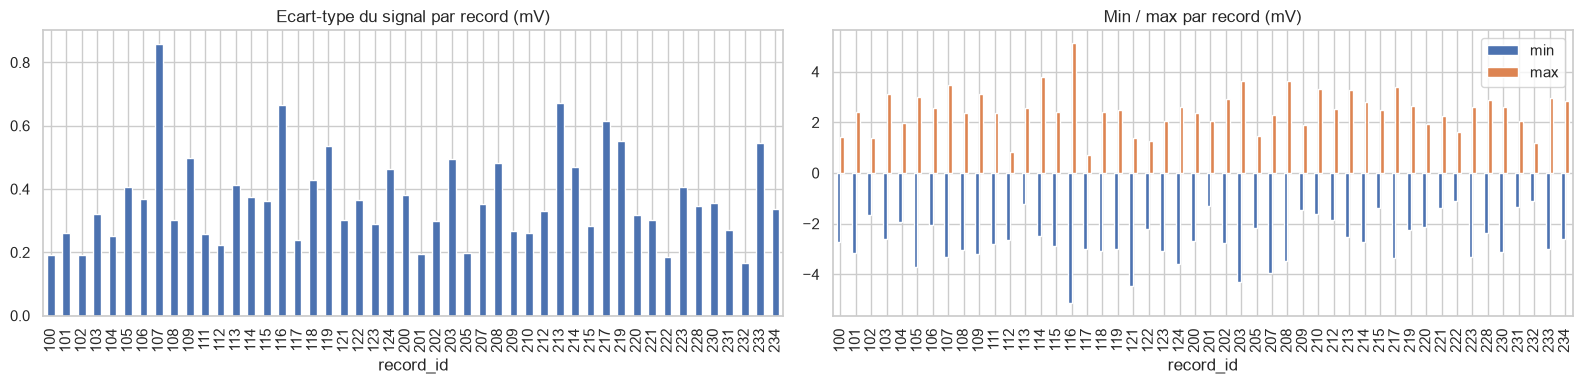

In [12]:
st = []
for rid in ALL_RECORDS:
    x = signals[rid].astype(np.float64)
    st.append({"record_id": rid, "mean": x.mean(), "std": x.std(), "min": x.min(),
               "max": x.max(), "p1": np.percentile(x, 1), "p99": np.percentile(x, 99),
               "skew": stats.skew(x), "kurtosis": stats.kurtosis(x)})
stat_df = pd.DataFrame(st).set_index("record_id").round(3)
print(stat_df.describe().round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
stat_df["std"].plot.bar(ax=axes[0], title="Ecart-type du signal par record (mV)")
stat_df[["min", "max"]].plot.bar(ax=axes[1], title="Min / max par record (mV)")
plt.tight_layout()
fig.savefig(FIG_DIR / "signal_stats_per_record.png", dpi=150)

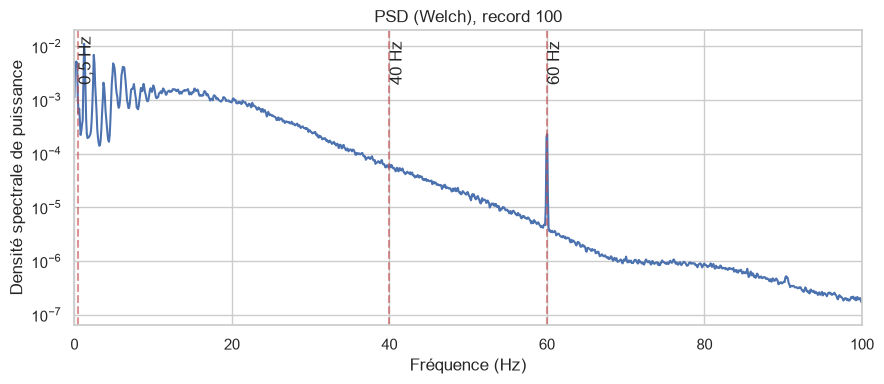

In [13]:
f, pxx = sps.welch(signals["100"].astype(np.float64), fs=FS, nperseg=4096)
plt.figure(figsize=(9, 4))
plt.semilogy(f, pxx)
for fx, lab in [(0.5, "0,5 Hz"), (40, "40 Hz"), (60, "60 Hz")]:
    plt.axvline(fx, ls="--", c="r", alpha=0.6); plt.text(fx, pxx.max() / 5, lab, rotation=90)
plt.xlabel("Fréquence (Hz)"); plt.ylabel("Densité spectrale de puissance")
plt.title("PSD (Welch), record 100"); plt.xlim(0, 100); plt.tight_layout()
plt.savefig(FIG_DIR / "psd_record100.png", dpi=150)

In [14]:
sym = all_ann.symbol.value_counts().rename("n").to_frame()
sym["description"] = sym.index.map(lambda s: SYMBOL_DESCRIPTIONS.get(s, "?"))
sym["type"] = np.where(sym.index.isin(AAMI_MAP), "battement", "non-battement")
sym["classe_AAMI"] = sym.index.map(lambda s: AAMI_MAP.get(s, "-"))
print(sym)

inconnus = [s for s in all_ann.symbol.unique() if s not in AAMI_MAP and s not in SYMBOL_DESCRIPTIONS]
print("\nSymboles ni mappés ni documentés (à examiner) :", inconnus)

            n                         description           type classe_AAMI
symbol                                                                      
N       75052                              Normal      battement           N
L        8075              Bloc de branche gauche      battement           N
R        7259               Bloc de branche droit      battement           N
V        7130    Extrasystole ventriculaire (PVC)      battement           V
/        7028                   Battement stimule      battement           Q
A        2546            Extrasystole auriculaire      battement           S
+        1291                Changement de rythme  non-battement           -
f         982             Fusion stimule + normal      battement           Q
F         803       Fusion ventriculaire + normal      battement           F
~         616     Changement de qualite du signal  non-battement           -
!         472               Flutter ventriculaire  non-battement           -

=== 48 records ===
           n  pourcentage
aami                    
N     90631       82.773
S      2781        2.540
V      7236        6.609
F       803        0.733
Q      8043        7.346

=== sans records stimulés (44 records) ===
           n  pourcentage
aami                    
N     90125       89.469
S      2781        2.761
V      7009        6.958
F       803        0.797
Q        15        0.015

Ratio d'imbalance (N / classe) :
 aami
N       1.0
S      32.4
V      12.9
F     112.2
Q    6008.3
Name: n, dtype: float64


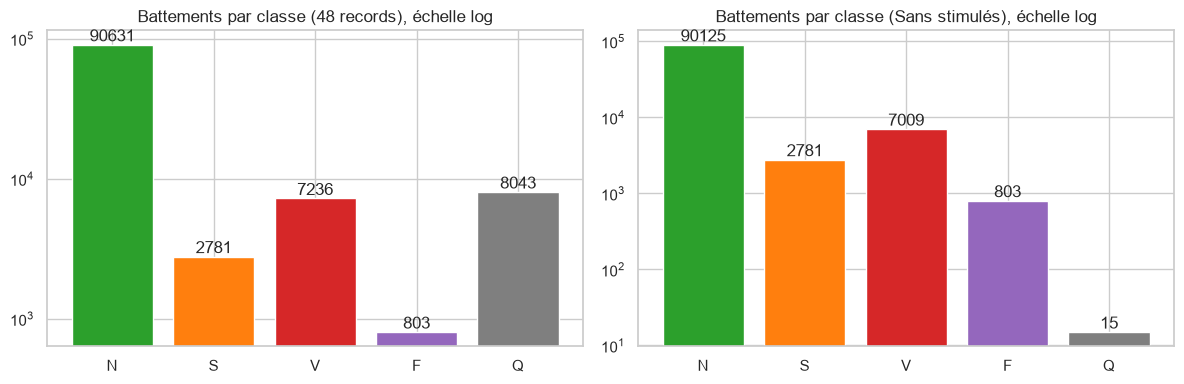

In [15]:
def class_table(df):
    c = df.aami.value_counts().reindex(CLASS_ORDER, fill_value=0)
    return pd.DataFrame({"n": c, "pourcentage": (100 * c / c.sum()).round(3)})

full = class_table(beats)
no_paced = class_table(beats[~beats.record_id.isin(PACED_RECORDS)])
print("=== 48 records ===\n", full)
print("\n=== sans records stimulés (44 records) ===\n", no_paced)

n_max = no_paced.n.max()
ratio = (n_max / no_paced.n.replace(0, np.nan)).round(1)
print("\nRatio d'imbalance (N / classe) :\n", ratio)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, tab, ttl in zip(axes, [full, no_paced], ["48 records", "Sans stimulés"]):
    ax.bar(tab.index, tab.n, color=[COLORS[c] for c in tab.index])
    ax.set_yscale("log"); ax.set_title(f"Battements par classe ({ttl}), échelle log")
    for i, v in enumerate(tab.n):
        ax.text(i, max(v, 1), str(v), ha="center", va="bottom")
plt.tight_layout()
fig.savefig(FIG_DIR / "class_distribution.png", dpi=150)

        DS1    DS2
aami              
N     45866  44259
S       944   1837
V      3788   3221
F       415    388
Q         8      7

Pourcentages :
         DS1    DS2
aami              
N     89.90  89.03
S      1.85   3.70
V      7.42   6.48
F      0.81   0.78
Q      0.02   0.01

Records avec au moins un F : ['108', '109', '114', '124', '200', '201', '202', '203', '205', '208', '210', '213', '214', '215', '219', '223', '233']


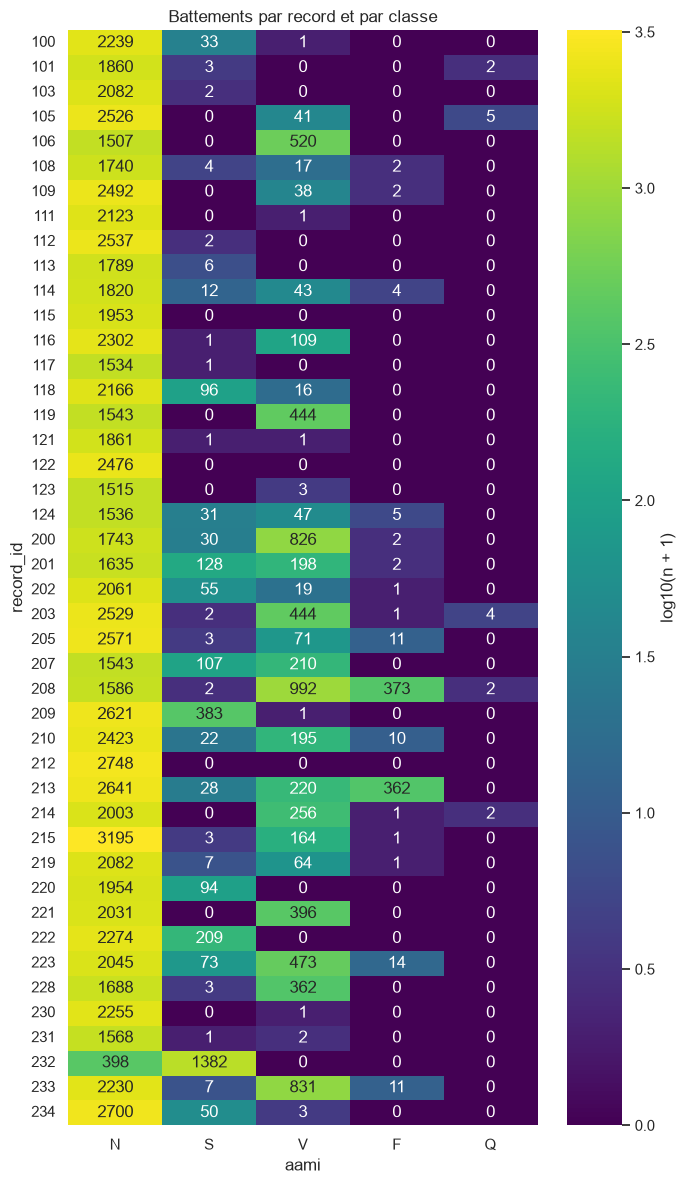

In [16]:
usable = beats[~beats.record_id.isin(PACED_RECORDS)]
per_rec = pd.crosstab(usable.record_id, usable.aami).reindex(columns=CLASS_ORDER, fill_value=0)

plt.figure(figsize=(7, 12))
sns.heatmap(np.log10(per_rec + 1), annot=per_rec, fmt="d", cmap="viridis",
            cbar_kws={"label": "log10(n + 1)"})
plt.title("Battements par record et par classe"); plt.tight_layout()
plt.savefig(FIG_DIR / "per_record_heatmap.png", dpi=150)

split = {"DS1": usable[usable.record_id.isin(DS1)], "DS2": usable[usable.record_id.isin(DS2)]}
split_tab = pd.DataFrame({k: v.aami.value_counts().reindex(CLASS_ORDER, fill_value=0)
                          for k, v in split.items()})
print(split_tab)
print("\nPourcentages :\n", (100 * split_tab / split_tab.sum()).round(2))
print("\nRecords avec au moins un F :", per_rec[per_rec.F > 0].index.tolist())

In [17]:
counts = no_paced.n.replace(0, np.nan)
weights = counts.sum() / (len(counts.dropna()) * counts)
print("Poids de classe 'balanced' (sur toute la base, pour illustration) :\n", weights.round(3))

Poids de classe 'balanced' (sur toute la base, pour illustration) :
 aami
N       0.224
S       7.244
V       2.874
F      25.089
Q    1343.107
Name: n, dtype: float64
